# DSSM–BG: A deep state-space Bernoulli–Gamma model for probabilistic daily precipitation downscaling

## Notation

| Symbol | Meaning | In the code |
|---|---|---|
| $\mathbf{x}_t\in\mathbb{R}^m$ | large-scale predictors of day $t$ ($m=8$), standardized | `x` |
| $y_t$ | precipitation at the station on day $t$ (mm), with the amounts $\le\tau$ set to 0 | `y_all` (numpy), `y_tensor` (torch) |
| $\tau$ | wet-day threshold, 1 mm | `CFG.tau` |
| $\delta_t=\mathbf{1}\{y_t>\tau\}$ | wet-day indicator | `wet` |
| $\boldsymbol\eta_t=(\alpha_t,\mu_t,\pi_t)$ | Bernoulli–Gamma parameters: shape, mean wet-day excess, wet-day probability | `alpha`, `mu`, `wet_probability` |
| $\mathbf{h}_t\in\mathbb{R}^{d_h}$ | deterministic context of the predictors, $d_h=32$ | `feature`, `DSSM.features` |
| $\mathbf{z}_t\in\mathbb{R}^{d_z}$ | stochastic latent state, $d_z=8$ | `z` |
| $\mathbf{c}_t$ | state of the inference network, 32 units | `context`, `hidden`, `DSSM.encode` |
| $\theta$, $\phi$ | parameters of the generative model and of the inference network | `generative`, `encoder` |
| $K$ | latent trajectories (particles) in training, 40 | `CFG.train_members` |
| $N$ | ensemble members in downscaling: 100 for validation, 1000 for the test period | `CFG.validation_members`, `CFG.test_members` |
| $L$, $M$ | training window (512 days) and context margin (64 days) | `CFG.window`, `CFG.context_margin` |
| $T_0$ | last day with observed precipitation: 31 December 2012 for validation, 31 December 2017 for the test period | last day of `train_rows`, of `history_rows` |

## 1. Setup

### 1.1 Environment and reproducibility

The model is small and is trained one day at a time, so we can use the CPU.

In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "1"          # one thread
os.environ["MKL_NUM_THREADS"] = "1"

import math
import platform
import random
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import torch
from IPython.display import display
from matplotlib.patches import Patch
from scipy import stats
from scipy.special import gammainc, gammaln, logsumexp
from scipy.stats import ks_2samp, rankdata
from torch import nn
from torch.nn import functional as F

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
pd.set_option("display.width", 160)

### 1.2 Configuration

| Setting | Symbol | Attribute of `Config` | Value |
|---|---|---|---|
| Wet-day threshold | $\tau$ | `tau` | 1 mm |
| Deterministic context | $\mathbf{h}_t\in\mathbb{R}^{d_h}$ | `hidden_dim` | bidirectional GRU, 16 units per direction, $d_h=32$ |
| Transition and emission networks | $f_\theta$, $g_\theta$ | `hidden_dim` | one hidden layer of 32 $\tanh$ units each |
| Inference network | $\mathrm{GRU}_\phi$ | `context_dim` | 32 units |
| Floors of the scales and of $\alpha_t$, $\mu_t$ | $s_{\min}$, $\epsilon$ | `epsilon_q`, `epsilon_alpha`, `epsilon_mu` | 0.01, $10^{-6}$ |
| Latent state | $\mathbf{z}_t\in\mathbb{R}^{d_z}$ | `latent_dim` | $d_z=8$ |
| Context margin and window | $M$, $L$ | `context_margin`, `window` | 64 and 512 days |
| Optimizer | | `learning_rate`, `gradient_clip` | Adam at $5\times10^{-4}$, gradient norm clipped at 5 |
| Particles in training | $K$ | `train_members` | 40 |
| Ensemble sizes | $N$ | `validation_members`, `test_members` | 100 for validation, 1000 for the test period |
| Model selection | | `validation_every`, `patience`, `improvement_tolerance`, `max_epochs` | fair CRPS every 5 epochs; stop after 6 validations without an improvement larger than $10^{-3}$, or after $10^4$ epochs |
| Seed of the run | | `seeds` | 456 |
| Predictors | $\mathbf{x}_t\in\mathbb{R}^m$ | `predictors` | $m=8$ daily ERA5 means |
| Periods | | `train_start`, …, `test_end` | training 1980–2012, validation 2013–2017, test 2018–2025 |

**The reasons for these values.**

- **Latent state, $d_z=8$.** It is large enough to carry several sources of local variability, and small enough that
  $K=40$ particles cover it in training.
- **Floors.** $s_{\min}$ and $\epsilon$ keep the Gaussian scales and the Gamma parameters away from zero, where the log
  densities diverge.
- **Windows of $L=512$ days.** Each window gives one parameter update.
- **Early stopping on the validation CRPS.** The checkpoint is chosen with a proper score of simulated ensembles. These are generated exactly as the test ensemble is.
- **At most $10^4$ epochs.** The limit only guarantees that the training ends. Early stopping ends it much earlier.

In [3]:
class Config:
    def __init__(self):
        # Latent and network dimensions, with numerical floors for the emission
        self.tau = 1.0
        self.hidden_dim = 32
        self.context_dim = 32
        self.epsilon_alpha = 1e-6
        self.epsilon_mu = 1e-6
        self.epsilon_q = 0.01

        # Latent state dimension. Training uses the stepwise importance-weighted objective with
        # DReG gradients for the encoder.
        self.latent_dim = 8

        # Bidirectional deterministic path (DSSM-BG): hidden_dim // 2 units per direction, and the number
        # of context days added on each side of a training window / before a forecast period.
        self.context_margin = 64

        # Optimisation, early stopping and ensemble sizes
        self.window = 512
        self.learning_rate = 5e-4
        self.gradient_clip = 5.0
        self.train_members = 40
        self.validation_members = 100
        self.test_members = 1000
        self.max_epochs = 10000
        self.validation_every = 5
        self.patience = 6
        self.improvement_tolerance = 1e-3
        self.seeds = (456,)

        # Predictors and seasons
        self.predictors = ("d2m_mean", "t2m_mean", "msl_mean", "tcwv_mean", "u850_mean", "v850_mean", "z850_mean", "q850_mean")
        self.seasons = {"DJF": (12, 1, 2), "MAM": (3, 4, 5), "JJA": (6, 7, 8), "SON": (9, 10, 11)}

        # Study periods
        self.train_start = "1980-01-01"
        self.train_end = "2012-12-31"
        self.validation_start = "2013-01-01"
        self.validation_end = "2017-12-31"
        self.test_start = "2018-01-01"
        self.test_end = "2025-12-31"

        # Station, device and input or output paths
        self.station = "tours"
        self.device = torch.device("cpu")
        root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "Data1Cell_06UTC").is_dir())
        self.era5_path = root / "data" / "Data1Cell_06UTC" / f"era5_daily_cell_{self.station}.npz"
        self.precipitation_path = root / "data" / "Data1Cell_06UTC" / f"ecad_rr_{self.station}_1980_2025.npy"
        self.output_dir = root / "results" / "notebook_dssm_bg"

    def as_dict(self):
        return {k: (str(v) if isinstance(v, (Path, torch.device)) else v) for k, v in vars(self).items()}


CFG = Config()
pd.Series({k: v for k, v in CFG.as_dict().items() if not k.endswith(("_path", "_dir"))}, dtype=object).to_frame("value")

,value
tau,1.0
hidden_dim,32
context_dim,32
epsilon_alpha,0.000001
epsilon_mu,0.000001
epsilon_q,0.01
latent_dim,8
context_margin,64
window,512
learning_rate,0.0005


## 2. Problem and data

We observe a paired sequence $\{(\mathbf{x}_t,y_t)\}_{t=1}^{T}$ at one station:

- $\mathbf{x}_t\in\mathbb{R}^m$ holds the $m=8$ daily predictors of the ERA5 reanalysis (Hersbach et al., 2020) for
  the grid cell that contains the station.
- $y_t$ is the precipitation measured at the station on day $t$, from the European Climate Assessment & Dataset
  (ECA&D; Klein Tank et al., 2002).

Amounts at or below the wet-day threshold $\tau=1$ mm are set to zero. They are trace amounts, which are recorded
inconsistently. Hence

$$
y_t\in\{0\}\cup(\tau,\infty),\qquad \delta_t=\mathbf{1}\{y_t>\tau\}.
$$

The predictors are known over the whole period $1{:}T$, from a reanalysis or from a climate model, whereas the
precipitation is observed only up to a day $T_0$, the last day of the observed record. The goal is the predictive
distribution of the following days,

$$
p\bigl(y_t\mid\mathbf{x}_{1:T},\,y_{1:T_0}\bigr),\qquad T_0<t\le T,
$$

represented by an ensemble of $N$ simulated daily series. The distribution of day $t$
may therefore depend on the predictors of the days before and after $t$, and on the observed precipitation up to
$T_0$.

**Splits.** The record is split in time and never shuffled.

| Period | Days | Use | $T_0$ |
|---|---|---|---|
| 1980–2012 | 12 054 | training | |
| 2013–2017 | 1826 | validation: selection of the checkpoint | 31 December 2012 |
| 2018–2025 | 2922 | test: evaluation only | 31 December 2017 |

When a period is downscaled, no observation after its $T_0$ is used.

**Scaling.** Each predictor $j$ is standardized with the mean $\bar x_j$ and the standard deviation $s_j$ of the
training period, $\tilde x_{t,j}=(x_{t,j}-\bar x_j)/s_j$. The same transformation is applied to every day, and the
validation and test periods are never used to fit it.

### 2.1 The station and the data

**Predictors.** The eight predictors of Table 2 come from the hourly ERA5 reanalysis at $0.25^\circ$. The ECA&D
precipitation of day $D$ is accumulated from 06 UTC on day $D$ to 06 UTC on day $D+1$. The hourly ERA5 values are
therefore averaged from 06 UTC on day $D$ to 05 UTC on day $D+1$, so that the predictors and the observation describe
the same 24 hours.

**Precipitation.** The predictand is the blended ECA&D series of the station, complete over 1980–2025.

In [4]:
with np.load(CFG.era5_path) as data:
    variable_names = data["variables"].astype(str).tolist()
    columns = [variable_names.index(name) for name in CFG.predictors]
    X_raw = data["data"][:, columns].astype(np.float64)
    dates = pd.DatetimeIndex(data["dates"].astype("datetime64[ns]"))

y_raw = np.load(CFG.precipitation_path).astype(np.float64)
y_all = np.where(y_raw <= CFG.tau, 0.0, y_raw)                # y_t in {0} U (tau, inf)
y_tensor = torch.tensor(y_all, dtype=torch.float32, device=CFG.device)
wet = y_all > CFG.tau                                          # delta_t
assert len(dates) == len(y_all) == 16_802 and (np.diff(dates.values) == np.timedelta64(1, "D")).all()

# Station: ECA&D identifier, coordinates and elevation; precipitation statistics from the series
display(pd.DataFrame({"ECA&D identifier (STAID)": [2190], "latitude (°N)": [47.44], "longitude (°E)": [0.73], "elevation (m)": [108],
                      "mean annual precipitation (mm)": [round(pd.Series(y_raw).groupby(dates.year).sum().mean())],
                      "wet days (%)": [round(100 * wet.mean(), 1)]}, index=["Tours"]))

UNITS = {"d2m_mean": ("2-m dew-point temperature", "°C"), "t2m_mean": ("2-m temperature", "°C"),
         "msl_mean": ("mean sea-level pressure", "hPa"), "tcwv_mean": ("total column water vapour", "kg m⁻²"),
         "u850_mean": ("zonal wind at 850 hPa", "m s⁻¹"), "v850_mean": ("meridional wind at 850 hPa", "m s⁻¹"),
         "z850_mean": ("geopotential height at 850 hPa", "m"), "q850_mean": ("specific humidity at 850 hPa", "g kg⁻¹")}
summary = pd.DataFrame(X_raw, columns=CFG.predictors).describe().T[["mean", "std", "min", "max"]]
summary.insert(0, "unit", [UNITS[name][1] for name in CFG.predictors])
summary.insert(0, "variable", [UNITS[name][0] for name in CFG.predictors])
print(f"{len(dates)} days, {dates[0].date()} to {dates[-1].date()}; "
      f"{np.mean(np.where(wet, 0, y_raw) > 0):.1%} of the days have a trace (0 < amount <= {CFG.tau:g} mm), set to 0")
display(summary.round(2))

,ECA&D identifier (STAID),latitude (°N),longitude (°E),elevation (m),mean annual precipitation (mm),wet days (%)
Tours,2190,47.44,0.73,108,681,28.4


16802 days, 1980-01-01 to 2025-12-31; 17.6% of the days have a trace (0 < amount <= 1 mm), set to 0


,variable,unit,mean,std,min,max
d2m_mean,2-m dew-point temperature,°C,7.78,5.36,-16.78,21.34
t2m_mean,2-m temperature,°C,12.00,6.51,-13.90,31.40
msl_mean,mean sea-level pressure,hPa,1017.19,8.62,964.65,1045.47
tcwv_mean,total column water vapour,kg m⁻²,17.52,7.12,1.94,43.83
u850_mean,zonal wind at 850 hPa,m s⁻¹,3.84,7.48,-20.71,32.70
v850_mean,meridional wind at 850 hPa,m s⁻¹,0.45,5.68,-19.33,29.47
z850_mean,geopotential height at 850 hPa,m,1486.11,74.88,1020.37,1670.78
q850_mean,specific humidity at 850 hPa,g kg⁻¹,4.39,1.94,0.13,10.89


### 2.2 Chronological split and standardization

The predictors are standardized with the mean and the standard deviation of the training period. The last two columns of the table give the persistence of wet and dry days: the probability of a wet day after a wet day (WW) and after a dry day (DW).

In [6]:
years = dates.year.to_numpy()
months = dates.month.to_numpy()
train_rows = np.flatnonzero((dates >= CFG.train_start) & (dates <= CFG.train_end))
validation_rows = np.flatnonzero((dates >= CFG.validation_start) & (dates <= CFG.validation_end))
test_rows = np.flatnonzero((dates >= CFG.test_start) & (dates <= CFG.test_end))
history_rows = np.concatenate([train_rows, validation_rows])

x_mean = X_raw[train_rows].mean(axis=0)
x_std = X_raw[train_rows].std(axis=0, ddof=0)
x_std = np.where(x_std == 0, 1.0, x_std)
X_standardized = (X_raw - x_mean) / x_std
x = torch.tensor(X_standardized, dtype=torch.float32, device=CFG.device)


def transitions(state):
    # P(wet | wet the day before) and P(wet | dry the day before), for a run of consecutive days
    previous, current = state[:-1], state[1:]
    return (previous & current).sum() / previous.sum(), (~previous & current).sum() / (~previous).sum()


split_rows = {"train": train_rows, "validation": validation_rows, "test": test_rows}
pd.DataFrame([{"split": name, "first": dates[rows[0]].date(), "last": dates[rows[-1]].date(), "days": len(rows),
               "wet days (%)": 100 * wet[rows].mean(), "mean (mm/day)": y_all[rows].mean(),
               "mean wet-day amount (mm)": y_all[rows][wet[rows]].mean(), "WW": transitions(wet[rows])[0],
               "DW": transitions(wet[rows])[1]} for name, rows in split_rows.items()]).set_index("split").round(3)

,first,last,days,wet days (%),mean (mm/day),mean wet-day amount (mm),WW,DW
split,,,,,,,,
train,1980-01-01,2012-12-31,12054,28.804,1.828,6.346,0.502,0.201
validation,2013-01-01,2017-12-31,1826,26.561,1.595,6.006,0.471,0.192
test,2018-01-01,2025-12-31,2922,28.097,1.730,6.156,0.512,0.190


### 2.3 A first look at the data

Figure shows three properties of the series that the model has to represent: the seasonal cycle, the persistence of
wet and dry days, and the skewed distribution of the wet-day amounts.

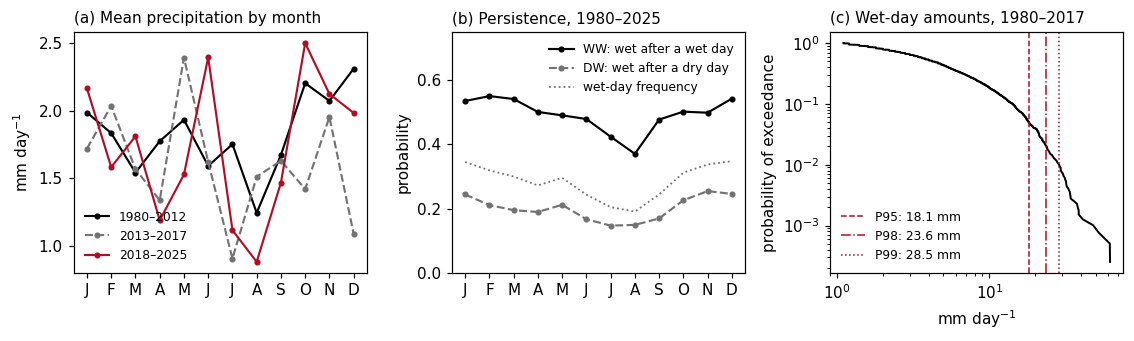

WW 0.501 against DW 0.198 over 1980–2025; skewness of the wet-day amounts of 1980–2017: 2.38


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.2), dpi=110)
month_names = list("JFMAMJJASOND")

# (a) mean precipitation by calendar month in the three periods
for name, label, line, color in (("train", "1980–2012", "-", "black"), ("validation", "2013–2017", "--", "0.45"),
                                 ("test", "2018–2025", "-", "#ae0f27")):
    rows = split_rows[name]
    by_month = pd.Series(y_all[rows]).groupby(months[rows]).mean()
    axes[0].plot(range(1, 13), by_month, line, color=color, lw=1.4, marker="o", ms=3, label=label)
axes[0].set(ylabel="mm day$^{-1}$", xticks=range(1, 13), xticklabels=month_names)
axes[0].set_title("(a) Mean precipitation by month", loc="left", fontsize=10)
axes[0].legend(frameon=False, fontsize=8)

# (b) persistence of wet and dry days by calendar month of the second day
previous, current = wet[:-1], wet[1:]
month_of_day = months[1:]
ww = [(previous & current)[month_of_day == m].sum() / previous[month_of_day == m].sum() for m in range(1, 13)]
dw = [(~previous & current)[month_of_day == m].sum() / (~previous)[month_of_day == m].sum() for m in range(1, 13)]
frequency = [current[month_of_day == m].mean() for m in range(1, 13)]
axes[1].plot(range(1, 13), ww, "-o", ms=3, lw=1.4, color="black", label="WW: wet after a wet day")
axes[1].plot(range(1, 13), dw, "--o", ms=3, lw=1.4, color="0.45", label="DW: wet after a dry day")
axes[1].plot(range(1, 13), frequency, ":", lw=1.2, color="0.45", label="wet-day frequency")
axes[1].set(ylabel="probability", ylim=(0, 0.75), xticks=range(1, 13), xticklabels=month_names)
axes[1].set_title("(b) Persistence, 1980–2025", loc="left", fontsize=10)
axes[1].legend(frameon=False, fontsize=8)

# (c) exceedance probability of the wet-day amounts of 1980-2017, with three upper percentiles
history_wet = np.sort(y_all[history_rows][wet[history_rows]])
exceedance = 1 - np.arange(1, len(history_wet) + 1) / (len(history_wet) + 1)     # Weibull plotting positions
axes[2].plot(history_wet, exceedance, color="black", lw=1.3)
for q, line in ((95, "--"), (98, "-."), (99, ":")):
    level = np.percentile(history_wet, q)
    axes[2].axvline(level, color="#ae0f27", ls=line, lw=1.0, label=f"P{q}: {level:.1f} mm")
axes[2].set(xscale="log", yscale="log", xlabel="mm day$^{-1}$", ylabel="probability of exceedance")
axes[2].set_title("(c) Wet-day amounts, 1980–2017", loc="left", fontsize=10)
axes[2].legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()
print(f"WW {transitions(wet)[0]:.3f} against DW {transitions(wet)[1]:.3f} over 1980–2025; "
      f"skewness of the wet-day amounts of 1980–2017: {stats.skew(history_wet):.2f}")

**Figure.** (a) Mean daily precipitation by calendar month in the three periods. (b) Probability of a wet day
after a wet day (WW) and after a dry day (DW), by calendar month of the second day, with the wet-day frequency.
(c) Probability that a wet-day amount of 1980–2017 exceeds a given value, on logarithmic axes, with the 95th, 98th
and 99th percentiles of the wet-day amounts.

**What the figure shows.**

- **Persistence.** A wet day is followed by another wet day much more often than a dry day is, in every month
  (panel b). Wet and dry days therefore come in spells. A model that draws each day independently can produce such
  spells only through the persistence of its predictors. DSSM–BG adds two sources of temporal dependence: a context
  that reads the predictors of the preceding and following days, and a latent state that carries the local
  variability from one day to the next.
- **Upper tail.** The wet-day amounts have a long upper tail, which the Gamma distribution of the excess $y_t-\tau$
  has to represent.

## 3. Model

DSSM–BG is a deep state-space model with a Bernoulli–Gamma emission. The Bernoulli–Gamma parameters $\boldsymbol\eta_t=(\alpha_t,\mu_t,\pi_t)$ of day $t$ depend on two components:

- a **deterministic context** $\mathbf{h}_t$, which summarizes the large-scale predictors;
- a **stochastic latent state** $\mathbf{z}_t$, which carries the local variability that the predictors do not
  explain from one day to the next.

DSSM–BG has two parts. The **generative model** defines the distribution of the
precipitation given the predictors. The **inference model** estimates the latent state from the predictors and the
observed precipitation. It is needed for training and for starting the downscaling at $T_0$.

| Component | Input and output | Attribute in the code | Parameters |
|---|---|---|---|
| Bernoulli–Gamma emission | $y_t$, $\boldsymbol\eta_t$ → $\log p(y_t\mid\boldsymbol\eta_t)$ | `bg_log_prob` | – |
| Deterministic context | $\mathbf{x}_{1:T}$ → $\mathbf{h}_t$ | `path` | $\theta$ |
| Latent transition $f_\theta$ | $[\mathbf{z}_{t-1};\mathbf{h}_t]$ → $\mathbf{m}_\theta$, $\mathbf{s}_\theta$ | `transition` | $\theta$ |
| Emission network $g_\theta$ | $[\mathbf{z}_t;\mathbf{h}_t]$ → $\alpha_t$, $\mu_t$, $\pi_t$ | `emission_head` | $\theta$ |
| Inference GRU | $\mathbf{a}_t$, $\mathbf{c}_{t-1}$ → $\mathbf{c}_t$ | `encoder` | $\phi$ |
| Inference head | $[\mathbf{z}_{t-1};\mathbf{c}_t]$ → $\mathbf{m}_\phi$, $\mathbf{s}_\phi$ | `posterior_out` | $\phi$ |

### 3.1 Bernoulli–Gamma emission

Given $\boldsymbol\eta_t$, day $t$ is wet with probability $\pi_t$, and the excess $y_t-\tau$ of a wet day follows a
Gamma distribution with shape $\alpha_t$ and mean $\mu_t$:

$$
p(y_t\mid\boldsymbol\eta_t)=(1-\pi_t)^{1-\delta_t}\left[\pi_t\,\frac{(\alpha_t/\mu_t)^{\alpha_t}}{\Gamma(\alpha_t)}\,
(y_t-\tau)^{\alpha_t-1}\exp\Bigl(-\frac{\alpha_t}{\mu_t}(y_t-\tau)\Bigr)\right]^{\delta_t}.
\tag{1}
$$

- **Mean–shape parameterization.** $\mu_t=\mathbb{E}[y_t-\tau\mid\delta_t=1]$ is the mean wet-day excess, the mean
  wet-day amount is $\tau+\mu_t$, and the code uses the rate $\beta_t=\alpha_t/\mu_t$. The variance of the excess is
  $\mu_t^2/\alpha_t$, so its coefficient of variation is $1/\sqrt{\alpha_t}$: a small $\alpha_t$ gives a skewed
  distribution of the amounts.
- **Why the excess $y_t-\tau$.** A wet amount is always larger than $\tau$. With the Gamma distribution on the
  excess, the wet-day component has the support $(\tau,\infty)$, with no mass between 0 and $\tau$.
- **A mixed measure.** A dry day contributes the probability $1-\pi_t$, and a wet day $\pi_t$ times a density. The
  likelihood is therefore defined with respect to a measure with an atom at zero, and the log density of a wet day can
  be positive.
- **Moments.** For one Bernoulli–Gamma distribution, $\mathbb{E}[y_t\mid\boldsymbol\eta_t]=\pi_t(\tau+\mu_t)$ and
  $\operatorname{Var}[y_t\mid\boldsymbol\eta_t]=\pi_t\bigl(\mu_t^2/\alpha_t+(\tau+\mu_t)^2\bigr)-\pi_t^2(\tau+\mu_t)^2$.

**The code.**

- `bg_log_prob` evaluates $\log p(y_t\mid\boldsymbol\eta_t)$ from the logit of $\pi_t$. Using $\log\sigma(\ell)$ and
  $\log\sigma(-\ell)$ is numerically stable for any logit $\ell$.
- A value in $(0,\tau]$ has probability zero under the model, so it gets $-\infty$. It cannot occur, because such
  amounts were set to 0.
- `gaussian_log_prob` is the log density of a diagonal Gaussian, summed over the $d_z$ coordinates. It is used for the
  transition prior and for the approximate posterior.

In [8]:
def bg_log_prob(y, wet_logit, alpha, beta):
    wet = y > CFG.tau
    excess = torch.where(wet, y - CFG.tau, torch.ones_like(y))
    gamma_log_prob = (alpha * torch.log(beta) - torch.lgamma(alpha) + (alpha - 1) * torch.log(excess) - beta * excess)
    log_prob = torch.where(wet, F.logsigmoid(wet_logit) + gamma_log_prob, F.logsigmoid(-wet_logit))
    return torch.where((y == 0) | wet, log_prob, torch.full_like(log_prob, -torch.inf))


def gaussian_log_prob(value, mean, std):
    # Diagonal Gaussian log density, summed over the latent dimension.
    return (-0.5 * math.log(2.0 * math.pi) - torch.log(std) - 0.5 * ((value - mean) / std) ** 2).sum(dim=-1)

### 3.2 Recurrent deterministic context

The context network summarizes the predictors into $\mathbf{h}_t\in\mathbb{R}^{d_h}$ with a bidirectional GRU:

$$
\overrightarrow{\mathbf{h}}_t=\overrightarrow{\mathrm{GRU}}_\theta(\mathbf{x}_t,\overrightarrow{\mathbf{h}}_{t-1}),\qquad
\overleftarrow{\mathbf{h}}_t=\overleftarrow{\mathrm{GRU}}_\theta(\mathbf{x}_t,\overleftarrow{\mathbf{h}}_{t+1}),\qquad
\mathbf{h}_t=[\overrightarrow{\mathbf{h}}_t;\overleftarrow{\mathbf{h}}_t],
\tag{2}
$$

with zero initial states. One GRU step with input $\mathbf{x}_t$ and previous state $\mathbf{h}_{t-1}$ is

$$
\begin{aligned}
\mathbf{r}_t&=\sigma(W_r\mathbf{x}_t+U_r\mathbf{h}_{t-1}+\mathbf{b}_r), &
\mathbf{u}_t&=\sigma(W_u\mathbf{x}_t+U_u\mathbf{h}_{t-1}+\mathbf{b}_u),\\
\mathbf{n}_t&=\tanh\bigl(W_n\mathbf{x}_t+\mathbf{r}_t\odot(U_n\mathbf{h}_{t-1}+\mathbf{b}_{hn})+\mathbf{b}_n\bigr), &
\mathbf{h}_t&=(1-\mathbf{u}_t)\odot\mathbf{n}_t+\mathbf{u}_t\odot\mathbf{h}_{t-1}.
\end{aligned}
$$

The reset gate $\mathbf{r}_t$ decides how much of the past enters the candidate $\mathbf{n}_t$, and the update gate
$\mathbf{u}_t$ how much of the old state is kept. The gates let the context keep information over many days.

- **Why bidirectional.** In the perfect-prognosis setting, the predictors are known over the whole period, also after
  $T_0$, so the backward recursion may read the following days. The forward recursion summarizes the current and
  preceding predictors, and the backward recursion the current and following ones.
- **Size.** With 16 units per direction, $d_h=32$.
- **Shared by the members.** The context is deterministic: all ensemble members share it.

### 3.3 Stochastic latent transition

The latent state $\mathbf{z}_t\in\mathbb{R}^{d_z}$ follows a nonlinear Gaussian transition conditioned on the context:

$$
p_\theta(\mathbf{z}_t\mid\mathbf{z}_{t-1},\mathbf{h}_t)=\mathcal{N}\bigl(\mathbf{z}_t;\,\mathbf{m}_\theta,\,
\operatorname{diag}(\mathbf{s}^2_\theta)\bigr),\qquad
[\mathbf{m}_\theta;\tilde{\mathbf{s}}_\theta]=f_\theta([\mathbf{z}_{t-1};\mathbf{h}_t]),\qquad
\mathbf{s}_\theta=s_{\min}+\operatorname{softplus}(\tilde{\mathbf{s}}_\theta),\qquad \mathbf{z}_0=\mathbf{0}.
\tag{3}
$$

- $f_\theta$ (`transition`) is an MLP with one hidden layer of 32 $\tanh$ units.
- The softplus keeps the scale positive and grows only linearly for large arguments, and $s_{\min}=0.01$ keeps it away
  from zero.
- The output bias of $\tilde{\mathbf{s}}_\theta$ starts at $\operatorname{softplus}^{-1}(0.5)=\log(e^{0.5}-1)$, so that
  $\mathbf{s}_\theta\approx0.5$ at the start of training. With a scale close to zero, the latent state would be almost
  deterministic, and the model could learn to ignore it.
- The latent state represents the local variability that the predictors do not explain, and the transition carries it
  from one day to the next.

### 3.4 Emission network

The Bernoulli–Gamma parameters are a nonlinear function of the latent state and the context:

$$
(\tilde\alpha_t,\tilde\mu_t,\tilde\pi_t)=g_\theta([\mathbf{z}_t;\mathbf{h}_t]),\qquad
\alpha_t=\epsilon+\operatorname{softplus}(\tilde\alpha_t),\quad
\mu_t=\epsilon+\operatorname{softplus}(\tilde\mu_t),\quad
\pi_t=\sigma(\tilde\pi_t).
\tag{4}
$$

$g_\theta$ (`emission_head`) also has one hidden layer of 32 $\tanh$ units, and $\epsilon=10^{-6}$. We write
$\boldsymbol\eta_\theta(\mathbf{z}_t,\mathbf{h}_t)$ for this map. Because $\boldsymbol\eta_t$ depends on the random
state $\mathbf{z}_t$, each member of the ensemble has its own parameters, and the predictive distribution is a mixture
of Bernoulli–Gamma distributions (Section 4.1).

### 3.5 Filtering inference network

The posterior of the latent states has no closed form, because the transition and the emission are nonlinear. It is
approximated by a GRU that reads the predictors and the observed precipitation through
$\mathbf{a}_t=[\mathbf{x}_t;\,\delta_t;\,\log(1+y_t)]$:

$$
\mathbf{c}_t=\mathrm{GRU}_\phi(\mathbf{a}_t,\mathbf{c}_{t-1}),\quad \mathbf{c}_0=\mathbf{0},\qquad
q_\phi(\mathbf{z}_t\mid\mathbf{z}_{t-1},\mathbf{c}_t)=\mathcal{N}\bigl(\mathbf{z}_t;\,\mathbf{m}_\phi,\,
\operatorname{diag}(\mathbf{s}^2_\phi)\bigr),
\tag{7}
$$

where $[\mathbf{m}_\phi;\tilde{\mathbf{s}}_\phi]$ is an affine function of $[\mathbf{z}_{t-1};\mathbf{c}_t]$
(`posterior_out`) and $\mathbf{s}_\phi=s_{\min}+\operatorname{softplus}(\tilde{\mathbf{s}}_\phi)$.

The reasons for each choice:

- **Wet indicator and log amount as inputs.** $\delta_t$ gives the occurrence explicitly, and $\log(1+y_t)$ compresses
  the skewed amounts, so that a few heavy days do not dominate the input.
- **Forward in time, without $\mathbf{h}_t$.** The network reads the data forward and does not use the context, so
  $q_\phi$ depends on the data only through $\mathbf{x}_{1:t}$ and $y_{1:t}$. It can therefore be run up to the last
  observed day $T_0$ and estimate the latent state there exactly as on the training days, without seeing any
  observation after $T_0$. The smoothing alternative of Appendix B, which also reads the following days, does not have
  this property.

### 3.6 The code

| Method | Computes |
|---|---|
| `initial` | $\mathbf{z}_0=\mathbf{0}$ for every member, and $\mathbf{c}_0=\mathbf{0}$ |
| `features` | the context $\mathbf{h}_t$; `pad = (left, right)` margin rows are read by the GRU and then cropped |
| `prior` | mean and scale of $p_\theta(\mathbf{z}_t\mid\mathbf{z}_{t-1},\mathbf{h}_t)$ |
| `encode` | the states $\mathbf{c}_t$ on a run of days, from a carried state |
| `posterior` | mean and scale of $q_\phi(\mathbf{z}_t\mid\mathbf{z}_{t-1},\mathbf{c}_t)$ |
| `emission` | $\alpha_t$, $\mu_t$, $\beta_t$, the logit of $\pi_t$ and $\pi_t$ of every member |

In [9]:
class DSSM(nn.Module):
    def __init__(self, input_dim, latent_dim):
        super().__init__()
        self.latent_dim = latent_dim

        # Deterministic context h_t: hidden_dim // 2 units per direction, so the context size is CFG.hidden_dim.
        self.path = nn.GRU(input_dim, CFG.hidden_dim // 2, batch_first=True, bidirectional=True)
        self.emission_head = nn.Sequential(nn.Linear(latent_dim + CFG.hidden_dim, CFG.hidden_dim), nn.Tanh(), nn.Linear(CFG.hidden_dim, 3))

        self.transition = nn.Sequential(nn.Linear(latent_dim + CFG.hidden_dim, CFG.hidden_dim), nn.Tanh(), nn.Linear(CFG.hidden_dim, 2 * latent_dim))

        # Encoder on a_t = [x_t, d_t, log(1 + y_t)]
        self.encoder = nn.GRU(input_dim + 2, CFG.context_dim, batch_first=True)
        self.posterior_out = nn.Linear(latent_dim + CFG.context_dim, 2 * latent_dim)

        self.register_buffer("anchor", torch.zeros(1))
        with torch.no_grad():
            # Start from a clearly stochastic transition
            self.transition[-1].bias[latent_dim:] = math.log(math.expm1(0.5))

    def initial(self, n_members):
        z = self.anchor.new_zeros(n_members, self.latent_dim)
        hidden = self.anchor.new_zeros(1, 1, CFG.context_dim)
        return z, hidden

    def features(self, x, pad=(0, 0)):
        # Context h_t; pad = (left, right) margin rows that are cropped away.
        context, _ = self.path(x.unsqueeze(0))
        return context[0, pad[0]:len(x) - pad[1]]

    def prior(self, z_previous, feature_t):
        inputs = torch.cat([z_previous, feature_t.expand(len(z_previous), -1)], dim=-1)
        mean, rho = self.transition(inputs).chunk(2, dim=-1)
        return mean, CFG.epsilon_q + F.softplus(rho)

    def encode(self, x, y, hidden):
        wet = (y > CFG.tau).to(x.dtype)
        gru_input = torch.cat([x, wet[:, None], torch.log1p(y)[:, None]], dim=-1)
        context, hidden = self.encoder(gru_input.unsqueeze(0), hidden)
        return context[0], hidden

    def posterior(self, z_previous, context_t):
        inputs = torch.cat([z_previous, context_t.expand(len(z_previous), -1)], dim=-1)
        mean, rho = self.posterior_out(inputs).chunk(2, dim=-1)
        return mean, CFG.epsilon_q + F.softplus(rho)

    def emission(self, z, feature_t):
        raw = self.emission_head(torch.cat([z, feature_t.expand(len(z), -1)], dim=-1))
        u, v, wet_logit = raw.unbind(dim=-1)
        alpha = CFG.epsilon_alpha + F.softplus(u)
        mu = CFG.epsilon_mu + F.softplus(v)
        return {"alpha": alpha, "mu": mu, "beta": alpha / mu, "wet_logit": wet_logit, "wet_probability": torch.sigmoid(wet_logit)}

### 3.7 Size of the model

The model is small. Its training takes time because the latent state is propagated day by day, not because of the
size of the networks.

In [10]:
example = DSSM(len(CFG.predictors), CFG.latent_dim)
blocks = {"context GRU (path)": "path", "transition f_theta": "transition", "emission g_theta": "emission_head",
          "inference GRU": "encoder", "inference head": "posterior_out"}
counts = {label: sum(p.numel() for n, p in example.named_parameters() if n.startswith(prefix)) for label, prefix in blocks.items()}
counts["total"] = sum(counts.values())
pd.Series(counts).to_frame("parameters")

,parameters
context GRU (path),2496
transition f_theta,1840
emission g_theta,1411
inference GRU,4224
inference head,656
total,10627


## 4. Learning

### 4.1 Joint density, predictive distribution and the need for inference

The joint density of the precipitation and the latent states given the predictors is

$$
p_\theta(y_{1:T},\mathbf{z}_{1:T}\mid\mathbf{x}_{1:T})=\prod_{t=1}^{T}p\bigl(y_t\mid\boldsymbol\eta_\theta(\mathbf{z}_t,\mathbf{h}_t)\bigr)\,
p_\theta(\mathbf{z}_t\mid\mathbf{z}_{t-1},\mathbf{h}_t),
\tag{5}
$$

and the predictive distribution of a day $T_0<t\le T$ is a continuous mixture of Bernoulli–Gamma distributions,

$$
p_\theta(y_t\mid\mathbf{x}_{1:T},y_{1:T_0})=\int p\bigl(y_t\mid\boldsymbol\eta_\theta(\mathbf{z}_t,\mathbf{h}_t)\bigr)\,
p_\theta(\mathbf{z}_t\mid\mathbf{x}_{1:T},y_{1:T_0})\,\mathrm{d}\mathbf{z}_t.
\tag{6}
$$

Its spread can therefore change with the latent state, whereas a model without latent state has one Bernoulli–Gamma
distribution per day, fixed by the predictors. The marginal likelihood $p_\theta(y_{1:T}\mid\mathbf{x}_{1:T})$ is the
integral of (5) over $\mathbf{z}_{1:T}$, which has no closed form. The model is therefore trained by variational
inference, with the filtering network $q_\phi$ as proposal.

### 4.2 Stepwise importance-weighted objective

$K$ latent trajectories are drawn from $q_\phi$ with the reparameterization trick. Trajectory $k$ starts from
$\mathbf{z}^{(k)}_0=\mathbf{0}$ and is drawn day by day,

$$
\mathbf{z}^{(k)}_t=\mathbf{m}_\phi(\mathbf{z}^{(k)}_{t-1},\mathbf{c}_t)+\mathbf{s}_\phi(\mathbf{z}^{(k)}_{t-1},\mathbf{c}_t)\odot\boldsymbol\varepsilon^{(k)}_t,
\qquad \boldsymbol\varepsilon^{(k)}_t\sim\mathcal{N}(\mathbf{0},\mathbf{I}),
$$

so that $\mathbf{z}^{(k)}_t$ is a differentiable function of $\phi$ and the gradients pass through the samples. On each
day, the log importance weight of trajectory $k$ compares the generative model with the proposal:

$$
\log w_t^{(k)}=\log p\bigl(y_t\mid\boldsymbol\eta_\theta(\mathbf{z}^{(k)}_t,\mathbf{h}_t)\bigr)
+\log p_\theta(\mathbf{z}^{(k)}_t\mid\mathbf{z}^{(k)}_{t-1},\mathbf{h}_t)
-\log q_\phi(\mathbf{z}^{(k)}_t\mid\mathbf{z}^{(k)}_{t-1},\mathbf{c}_t),
\tag{8}
$$

and the model maximizes the stepwise importance-weighted objective

$$
\mathcal{L}_K(\theta,\phi)=\frac{1}{T}\sum_{t=1}^{T}\log\Bigl(\frac{1}{K}\sum_{k=1}^{K}w_t^{(k)}\Bigr).
\tag{9}
$$

**How it relates to the usual bounds.**

- For $K=1$, the expectation of $T\mathcal{L}_1$ is the evidence lower bound (ELBO).
- For $K>1$, the average inside the logarithm is the importance-weighted estimator of Burda et al. (2016), applied on
  every day.
- The trajectories are propagated without resampling, so $\mathcal{L}_K$ is a training objective and not a guaranteed
  lower bound on $\log p_\theta(y_{1:T}\mid\mathbf{x}_{1:T})$. Its value is not used to select the model: Section 6
  selects the checkpoint with the CRPS of simulated ensembles.

**What the code computes.** It minimizes `nll` $=-\mathcal{L}_K$ with a `logsumexp`, which is numerically stable:
$\log\frac1K\sum_k w^{(k)}_t=\operatorname{logsumexp}_k\log w^{(k)}_t-\log K$. It also reports the effective sample
size of the normalized weights $W^{(k)}_t=w^{(k)}_t/\sum_{k'}w^{(k')}_t$,

$$
\mathrm{ESS}_t=\Bigl(\sum_{k=1}^{K}\bigl(W^{(k)}_t\bigr)^2\Bigr)^{-1}\in[1,K],
$$

averaged over the days. An ESS close to $K$ means that the proposal $q_\phi$ is close to the posterior, so that every
particle carries a similar weight. An ESS close to 1 means that one particle carries all the weight.

### 4.3 Doubly reparameterized gradients

- **Generative parameters $\theta$.** They receive the gradient of $\mathcal{L}_K$.
- **Inference parameters $\phi$.** The signal-to-noise ratio of the standard gradient decreases as $K$ increases
  (Rainforth et al., 2018). These parameters are therefore updated with the doubly reparameterized gradient estimator
  (DReG) of Tucker et al. (2019):

$$
\widehat{\nabla}_\phi\mathcal{L}_K=\frac{1}{T}\sum_{t=1}^{T}\sum_{k=1}^{K}\bigl(W_t^{(k)}\bigr)^2\,
\frac{\mathrm{d}\log\breve w_t^{(k)}}{\mathrm{d}\phi},
\tag{10}
$$

where $\breve w_t^{(k)}$ is the weight (8) with the parameters of $q_\phi$ held fixed in the density $\log q_\phi$, so
that $\phi$ acts only through the samples $\mathbf{z}^{(k)}_t$, and the normalized weights are treated as constants.

**The surrogate in the code.**

- `frozen_weights` holds the log-weights computed with `q_mean.detach()` and `q_std.detach()`: these are the
  $\log\breve w^{(k)}_t$.
- The surrogate is $-\frac{1}{T}\sum_t\sum_k\operatorname{sg}\bigl[(W^{(k)}_t)^2\bigr]\log\breve w^{(k)}_t$, where
  $\operatorname{sg}$ stops the gradient. Its gradient with respect to $\phi$ is $-\widehat{\nabla}_\phi\mathcal{L}_K$.
  Detaching does not change the values, so the normalized weights of $\breve w$ equal those of $w$.
- Two backward passes are made on every window: the gradient of `nll` for $\theta$, and that of the surrogate for
  $\phi$.

### 4.4 Training on windows

The training record is one sequence of 12 054 days. Back-propagating through it would store the $K$ trajectories of
every day and allow one parameter update per pass. Training uses instead truncated back-propagation through time:

- **Windows.** The record is split into consecutive windows of $L=512$ days, processed in chronological order, with
  one parameter update per window. At Tours, an epoch has 23 windows of 512 days and a last window of 278 days.
- **Carried states.** The particles $\mathbf{z}^{(k)}$ and the state $\mathbf{c}$ of the inference network are carried
  from one window to the next, so that the latent trajectories and the filtering run over a continuous sequence. The
  gradients are stopped at the window boundaries (`detach`).
- **Margins of the context.** The bidirectional context cannot be carried: on the last days of a window, the backward
  recursion needs days of the next window. Each window is therefore extended by $M=64$ predictor days on each side
  (`x_path`), and the context is computed on the extended window from zero states. The outputs on the margins are
  discarded (`pad`). The margins let both recursions forget their zero initial states before they reach the window.
  The first window has no left margin and the last no right margin.

The extended windows overlap by $2M$ days, but the windows do not, so each day enters the objective once per epoch.
This scheme is adapted from the context-sensitive chunks used to train bidirectional recurrent networks on long speech
sequences (Chen et al., 2015). Unlike those chunks, the windows are processed in order, because the particles and the
state of the inference network are carried.

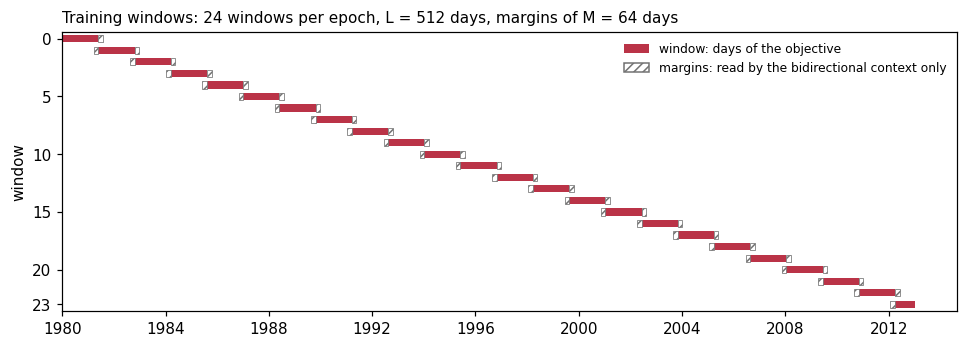

In [11]:
# The windows of one epoch, as train_chain builds them
fig, ax = plt.subplots(figsize=(10.5, 3.3), dpi=110)
train_dates = dates[train_rows]
starts = list(range(0, len(train_rows), CFG.window))
for j, start in enumerate(starts):
    stop = min(start + CFG.window, len(train_rows))
    path_start = max(0, start - CFG.context_margin)
    path_stop = min(len(train_rows), stop + CFG.context_margin)
    ax.barh(j, (train_dates[stop - 1] - train_dates[start]).days + 1, left=train_dates[start], height=0.62,
            color="#ae0f27", alpha=0.85)
    for a, b in ((path_start, start), (stop, path_stop)):
        if b > a:
            ax.barh(j, (train_dates[b - 1] - train_dates[a]).days + 1, left=train_dates[a], height=0.62, color="white",
                    edgecolor="0.45", hatch="////", linewidth=0.5)
ax.set(yticks=[0, 5, 10, 15, 20, len(starts) - 1], ylabel="window", ylim=(len(starts) - 0.4, -0.6))
ax.set_title(f"Training windows: {len(starts)} windows per epoch, L = {CFG.window} days, "
             f"margins of M = {CFG.context_margin} days", loc="left", fontsize=10)
ax.legend(handles=[Patch(facecolor="#ae0f27", alpha=0.85, label="window: days of the objective"),
                   Patch(facecolor="white", edgecolor="0.45", hatch="////", label="margins: read by the bidirectional context only")],
          loc="upper right", frameon=False, fontsize=8)
plt.show()

**Figure.** The windows of one epoch over the training period 1980–2012. Each window (filled) contributes its days
to the objective; the hatched margins are read only by the bidirectional context. The particles and the state of the
inference network pass from the end of one window to the start of the next.

### 4.5 The code

`train_window` computes one window: the context on the extended window, the inference states, the $K$ trajectories,
their log-weights, the objective, the DReG surrogate and the ESS. It returns the particles and the inference state to
carry to the next window. The noise is drawn from the generator `rng` of the chain, so that each chain is
reproducible on its own.

In [12]:
def train_window(model, x, y, z_previous, hidden, rng, x_path, pad):
    # One truncated-backpropagation window of the stepwise importance-weighted objective.
    # Returns (nll, dreg_surrogate, ess, z, hidden). nll gives the gradients of the
    # generative parameters; dreg_surrogate gives the DReG gradients of the encoder.
    feature = model.features(x_path, pad)
    context, hidden = model.encode(x, y, hidden)

    n_members = len(z_previous)
    log_weights, frozen_weights = [], []

    for t in range(len(y)):
        p_mean, p_std = model.prior(z_previous, feature[t])
        noise = torch.randn(p_std.shape, dtype=x.dtype, device=x.device, generator=rng)
        q_mean, q_std = model.posterior(z_previous, context[t])
        z = q_mean + q_std * noise

        eta = model.emission(z, feature[t])
        log_emission = bg_log_prob(y[t], eta["wet_logit"], eta["alpha"], eta["beta"])
        transition = gaussian_log_prob(z, p_mean, p_std)
        log_weights.append(log_emission + transition - gaussian_log_prob(z, q_mean, q_std))
        # Copy with the q parameters stopped, used only in the DReG surrogate.
        frozen_weights.append(log_emission + transition - gaussian_log_prob(z, q_mean.detach(), q_std.detach()))
        z_previous = z

    stacked = torch.stack(log_weights)
    bound = torch.logsumexp(stacked, dim=1) - math.log(n_members)
    nll = -bound.mean()
    normalised = torch.softmax(stacked, dim=1)
    ess = (1.0 / normalised.square().sum(dim=1)).mean()

    frozen = torch.stack(frozen_weights)
    weights = torch.softmax(frozen, dim=1).detach()
    surrogate = -(weights.square() * frozen).sum(dim=1).mean()
    return nll, surrogate, ess, z_previous, hidden

## 5. Downscaling

The downscaling of a target period uses the observed precipitation only up to $T_0$.
It has three steps:

1. **Filtering** (`filter_history`). The inference network runs over the observed record $1{:}T_0$ and draws $N$
   latent trajectories from $q_\phi$. Their final states $\mathbf{z}^{(n)}_{T_0}$ are the initial condition.
2. **Context of the target period.** The bidirectional GRU runs on $\mathbf{x}_{T_0-M+1:T}$: the target period,
   preceded by the $M$ days up to $T_0$ (`x_left`), which let the forward recursion forget its zero initial state. The
   outputs on these $M$ days are discarded. All members share this context.
3. **Prior propagation** (`propagate_prior`). For $T_0<t\le T$, each trajectory follows the transition prior, and a
   precipitation value is drawn from its emission:

$$
\mathbf{z}^{(n)}_t\sim p_\theta(\mathbf{z}^{(n)}_t\mid\mathbf{z}^{(n)}_{t-1},\mathbf{h}_t),\qquad
\boldsymbol\eta^{(n)}_t=\boldsymbol\eta_\theta(\mathbf{z}^{(n)}_t,\mathbf{h}_t),\qquad
y^{(n)}_t\sim p(y^{(n)}_t\mid\boldsymbol\eta^{(n)}_t),\qquad n=1,\ldots,N.
\tag{11}
$$

No observation after $T_0$ is used in Step 3. The procedure approximates the filtering distribution at $T_0$ by
$q_\phi$, and propagates the latent state with the transition prior.

**What the ensemble represents.** On each day, the $N$ members form a sample from the Monte Carlo approximation
$\frac{1}{N}\sum_n p(y_t\mid\boldsymbol\eta^{(n)}_t)$ of the mixture (6). Each member is a whole trajectory with its
own parameters $\boldsymbol\eta^{(n)}_t$, so the ensemble also keeps the dependence from one day to the next.

**Details of the code.**

- **Seeds.** Separate seeds are used for the filtering ($s+1$), the transition noise ($s+2$) and the emission draws
  ($s+3$), where $s$ is the seed of the downscaling.
- **Noise switch.** `noise_scale=0` switches off the transition noise after $T_0$, so that each member follows the mean
  path $\mathbf{m}_\theta$. In this study, we uses it to measure what the latent noise adds.
- **Wet amounts.** A wet amount is $\tau$ plus a Gamma draw. It is kept strictly above $\tau$ (`nextafter`), so that it
  is never mistaken for a dry day.

In [13]:
@torch.no_grad()
def filter_history(model, x_history, y_history, n_members, seed):
    # Run the encoder over the observed history and sample the boundary state z_T0.
    z, hidden = model.initial(n_members)
    rng = make_generator(model, seed)
    context, hidden = model.encode(x_history, y_history, hidden)
    for t in range(len(y_history)):
        mean, std = model.posterior(z, context[t])
        z = mean + std * torch.randn(std.shape, dtype=z.dtype, device=z.device, generator=rng)
    return z


@torch.no_grad()
def propagate_prior(model, x_future, boundary, transition_seed, emission_seed, noise_scale=1.0, x_left=None):
    # Prior propagation from the boundary state. x_left: predictor rows placed before x_future
    # as left context of the BiGRU (cropped).
    z = boundary.clone()
    transition_rng = make_generator(model, transition_seed)
    feature = model.features(torch.cat([x_left, x_future]), (len(x_left), 0))
    fields = ["rainfall", "alpha", "mu", "beta", "wet_logit", "wet_probability"]
    output = {name: [] for name in fields}

    tau_tensor = torch.tensor(CFG.tau, dtype=torch.float64, device=z.device)
    minimum_wet = torch.nextafter(tau_tensor, torch.full_like(tau_tensor, torch.inf))
    cuda_devices = [z.device.index] if z.is_cuda else []

    with torch.random.fork_rng(devices=cuda_devices):
        torch.manual_seed(emission_seed)
        for t in range(len(x_future)):
            mean, std = model.prior(z, feature[t])
            noise = torch.randn(std.shape, dtype=z.dtype, device=z.device, generator=transition_rng)
            z = mean + noise_scale * std * noise
            eta = model.emission(z, feature[t])
            gamma = torch.distributions.Gamma(eta["alpha"].double(), eta["beta"].double()).sample()
            wet = torch.rand_like(gamma) < eta["wet_probability"]
            amount = torch.maximum(CFG.tau + gamma, minimum_wet)
            values = {"rainfall": torch.where(wet, amount, torch.zeros_like(amount)), **eta}
            for name in fields:
                output[name].append(values[name].cpu())
    return {name: torch.stack(values).numpy() for name, values in output.items()}


def predict(model, x_history, y_history, x_future, n_members, seed, noise_scale=1.0):
    # Filter the history, then propagate the prior over x_future.
    boundary = filter_history(model, x_history, y_history, n_members, seed + 1)
    x_left = x_history[-CFG.context_margin:]
    return propagate_prior(model, x_future, boundary, transition_seed=seed + 2, emission_seed=seed + 3, noise_scale=noise_scale, x_left=x_left)

## 6. Training with model selection

- **Optimizer.** Adam at a learning rate of $5\times10^{-4}$, with one step per window. The joint gradient norm of
  $(\theta,\phi)$ is clipped at 5, so that a window with extreme amounts cannot produce a very large update.
- **Validation.** Every 5 epochs, the model downscales the validation period 2013–2017 with 100 members, exactly as
  the test period is downscaled later: the record 1980–2012 is filtered, and the prior is then propagated. The
  ensemble is scored with the fair CRPS,

$$
\widehat{\mathrm{CRPS}}_t=\frac{1}{N}\sum_{n=1}^{N}\bigl|y^{(n)}_t-y_t\bigr|
-\frac{1}{2N(N-1)}\sum_{n=1}^{N}\sum_{n'=1}^{N}\bigl|y^{(n)}_t-y^{(n')}_t\bigr|,
$$

  averaged over the days. The factor $N(N-1)$ makes the expected score independent of the ensemble size, so that the
  validation ensembles of 100 members and the test ensemble of 1000 members are scored on the same scale.
- **Checkpoint.** The checkpoint with the lowest validation CRPS is saved.
- **Stopping rule.** Training stops after 6 validations without an improvement larger than $10^{-3}$.

**Seeds.** The seed of the chain sets the initial parameters, through the global generator of torch, and the generator
of the training noise. The validation ensembles use the seed of the chain plus 20 000, and the test ensemble plus
30 000.

In [14]:
def threshold_precipitation(values, threshold=1.0):
    # Set precipitation at or below the wet-day threshold to zero.
    values = np.asarray(values, dtype=float)
    return np.where(values > threshold, values, 0.0)


def crps_ensemble_fair(observed, ensemble, threshold=1.0):
    # Daily fair ensemble CRPS; ensemble shape is (time, member).
    observed = threshold_precipitation(observed, threshold)
    ensemble = threshold_precipitation(ensemble, threshold)
    n_members = ensemble.shape[1]
    if n_members < 2:
        return np.full(observed.shape, np.nan, dtype=float)

    first_term = np.mean(np.abs(ensemble - observed[:, None]), axis=1)
    ordered = np.sort(ensemble, axis=1)
    coefficients = 2.0 * np.arange(1, n_members + 1) - n_members - 1.0
    pairwise_sum = np.sum(ordered * coefficients[None, :], axis=1)
    correction = pairwise_sum / (n_members * (n_members - 1.0))
    return first_term - correction


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed % (2**32))
    torch.manual_seed(seed)


def make_generator(model, seed):
    # Independent generator per sampler, so each chain is reproducible on its own.
    return torch.Generator(device=next(model.parameters()).device).manual_seed(seed)


def train_chain(x_train, y_train, x_validation, y_validation, seed, checkpoint_path, metadata):
    # Train one chain with early stopping on the validation fair CRPS.
    set_seed(seed)
    model = DSSM(x_train.shape[1], CFG.latent_dim).to(x_train.device)
    optimizer = torch.optim.Adam(model.parameters(), lr=CFG.learning_rate)
    rng = make_generator(model, seed)

    encoder_names = ("encoder", "posterior_out")
    encoder = [p for name, p in model.named_parameters() if name.startswith(encoder_names)]
    generative = [p for name, p in model.named_parameters() if not name.startswith(encoder_names)]

    best_crps, patience_crps, bad_checks, history = float("inf"), float("inf"), 0, []
    observed_validation = y_validation.cpu().numpy()

    for epoch in range(1, CFG.max_epochs + 1):
        model.train()
        z, hidden = model.initial(CFG.train_members)
        totals = np.zeros(3)

        for start in range(0, len(y_train), CFG.window):
            stop = min(start + CFG.window, len(y_train))
            optimizer.zero_grad(set_to_none=True)
            path_start = max(0, start - CFG.context_margin)
            path_stop = min(len(y_train), stop + CFG.context_margin)
            x_path, pad = x_train[path_start:path_stop], (start - path_start, path_stop - stop)
            nll, surrogate, ess, z, hidden = train_window(model, x_train[start:stop], y_train[start:stop], z, hidden, rng, x_path=x_path, pad=pad)

            # Generative parameters: gradient of the objective. Encoder: DReG surrogate.
            generative_grads = torch.autograd.grad(nll, generative, retain_graph=True, allow_unused=True)
            encoder_grads = torch.autograd.grad(surrogate, encoder, allow_unused=True)
            for parameter, gradient in zip(generative + encoder, list(generative_grads) + list(encoder_grads)):
                parameter.grad = torch.zeros_like(parameter) if gradient is None else gradient

            nn.utils.clip_grad_norm_(model.parameters(), CFG.gradient_clip)
            optimizer.step()
            z, hidden = z.detach(), hidden.detach()
            totals += np.array([float(nll.detach()), float(nll.detach()), float(ess.detach())]) * (stop - start)

        log = dict(zip(("loss", "nll", "ess"), totals / len(y_train)))
        log["epoch"] = epoch
        log["validation_crps"] = np.nan

        if epoch % CFG.validation_every == 0 or epoch == CFG.max_epochs:
            model.eval()
            validation_prediction = predict(model, x_train, y_train, x_validation, CFG.validation_members, seed + 20000)
            crps = float(crps_ensemble_fair(observed_validation, validation_prediction["rainfall"], CFG.tau).mean())
            log["validation_crps"] = crps

            if crps < best_crps:
                best_crps = crps
                checkpoint = {
                    "state_dict": {name: value.detach().cpu().clone()
                                   for name, value in model.state_dict().items()},
                    "input_dim": x_train.shape[1], "epoch": epoch,
                    "validation_crps": crps, "seed": seed,
                    "settings": CFG.as_dict(), "metadata": metadata,
                }
                torch.save(checkpoint, checkpoint_path)

            if crps < patience_crps - CFG.improvement_tolerance:
                patience_crps, bad_checks = crps, 0
            else:
                bad_checks += 1

            print(f"{metadata['variant']}/{metadata['group']} | epoch {epoch} | " f"loss {log['loss']:.4f} | ess {log['ess']:.1f} | " f"validation CRPS {crps:.4f}", flush=True)

        history.append(log)
        if bad_checks >= CFG.patience:
            break

    checkpoint = torch.load(checkpoint_path, map_location=x_train.device, weights_only=False)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    model.requires_grad_(False)
    return model, pd.DataFrame(history), checkpoint

At the Annual scale, the training period is one chain, `ALL`, with all the days. As in `run_dssm_parallel.py`, its
seed is derived from the seed of the run, the index of the training scale (Annual: 0) and the index of the group
(`ALL`: 0) with `numpy.random.SeedSequence`. The cell below trains the chain until early stopping, printing one line
per validation, and saves the kept checkpoint and the training log in `results/notebook_dssm_bg_tours/`.

In [ ]:
variant, group, seed = "DSSM_Annual", "ALL", CFG.seeds[0]
chain_seed = int(np.random.SeedSequence([seed, 0, 0]).generate_state(1)[0])
CFG.output_dir.mkdir(parents=True, exist_ok=True)
metadata = {"variant": variant, "group": group, "scaler_mean": x_mean.tolist(), "scaler_std": x_std.tolist(),
            "train_first": str(dates[train_rows[0]].date()), "train_last": str(dates[train_rows[-1]].date())}

started = time.perf_counter()
model, training_log, checkpoint = train_chain(x[train_rows], y_tensor[train_rows], x[validation_rows], y_tensor[validation_rows],
                                              chain_seed, CFG.output_dir / f"{group}.pt", metadata)
training_log.to_excel(CFG.output_dir / f"{group}_training.xlsx", index=False)
print(f"\nchain seed {chain_seed}: {len(training_log)} epochs in {(time.perf_counter() - started) / 60:.0f} min; "
      f"kept epoch {checkpoint['epoch']} (validation CRPS {checkpoint['validation_crps']:.4f})")

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.2), dpi=110)
valid = training_log.dropna(subset=["validation_crps"])
axes[0].plot(training_log.epoch, training_log.loss, color="#ae0f27", lw=1.2)
axes[0].set_yscale("log")
axes[0].set_yticks([1.0, 1.2, 1.5, 2.0], labels=["1.0", "1.2", "1.5", "2.0"])
axes[0].minorticks_off()
axes[1].plot(training_log.epoch, training_log.ess, color="#ae0f27", lw=1.2)
axes[1].axhline(CFG.train_members, color="0.45", ls=":", lw=0.9)
axes[1].set_ylabel(f"of K = {CFG.train_members} particles")
axes[2].plot(valid.epoch, valid.validation_crps, "-o", color="#ae0f27", lw=1.2, ms=2.5)
axes[2].axvline(checkpoint["epoch"], color="black", ls=":", lw=0.9)
axes[2].annotate(f"kept: epoch {checkpoint['epoch']}", (checkpoint["epoch"], checkpoint["validation_crps"]), xytext=(-80, 30),
                 textcoords="offset points", fontsize=8, arrowprops={"arrowstyle": "-", "color": "0.45", "lw": 0.8})
axes[2].set_ylabel("mm day$^{-1}$")
for ax, title in zip(axes, ("(a) Loss $-\\mathcal{L}_K$ per day", "(b) Mean effective sample size", "(c) Validation CRPS, 2013–2017")):
    ax.set_xlabel("epoch")
    ax.set_title(title, loc="left", fontsize=10)
fig.tight_layout()
plt.show()

**Figure.** (a) Loss $-\mathcal{L}_K$ per day, on a logarithmic axis. (b) Mean
effective sample size of the $K=40$ particles. (c) Validation CRPS every 5 epochs, with the kept epoch.

**What the figure shows.**

- **Loss.** It decreases fast in the first epochs and slowly afterwards.
- **ESS.** It rises within a few tens of epochs to more than 35 of the 40 particles and stays there: the filtering
  network has learned a proposal close to the posterior of the latent state.
- **Validation CRPS.** It keeps decreasing for much longer than the loss, because the checkpoint is selected on the
  forecasts and not on the objective. In the paper run, it fell from 1.31 mm day$^{-1}$ at epoch 5 to 0.87 at
  epoch 100 and 0.82 at epoch 245, the kept epoch, and early stopping ended the training 30 epochs later.

## 7. Evaluation on the test period 2018–2025

### 7.1 The test ensemble

The trained model downscales the test period twice with the seed of the chain plus 30 000 with the transition noise switched off after $T_0$. The
inference network filters 1980–2017, so that $T_0$ is 31 December 2017, and the context runs from 29 October 2017
($M=64$ days before $T_0$) to 31 December 2025.

In [ ]:
started = time.perf_counter()
prediction = predict(model, x[history_rows], y_tensor[history_rows], x[test_rows], CFG.test_members, chain_seed + 30000)
quiet = predict(model, x[history_rows], y_tensor[history_rows], x[test_rows], CFG.test_members, chain_seed + 30000, noise_scale=0.0)
observed = y_all[test_rows]
test_dates = dates[test_rows]
print(f"two test ensembles of {CFG.test_members} members x {len(test_rows)} days in {time.perf_counter() - started:.0f} s")
pd.DataFrame({name: [values.shape, values.dtype] for name, values in prediction.items()}, index=["shape (days, members)", "type"]).T

### 7.2 Probabilistic and predictive scores

Let $\mathcal{T}$ be the 2922 test days, $y_t$ the observation and $y^{(1)}_t,\ldots,y^{(N)}_t$ the members of day $t$. The scores are proper scoring rules or measures of discrimination (Gneiting and
Raftery, 2007):

- **CRPS**: the fair ensemble estimator, averaged over $\mathcal{T}$, in mm day$^{-1}$.
- **NLL**: $-\frac{1}{|\mathcal{T}|}\sum_t\log\bigl(\frac{1}{N}\sum_n p(y_t\mid\boldsymbol\eta^{(n)}_t)\bigr)$,
  the negative log density of the mixture of the members at the observation.
- **Brier score** and **AUC**  of the wet-day probability
  $\bar\pi_t=\frac{1}{N}\sum_n\pi^{(n)}_t$. The AUC is the probability that a wet day receives a higher probability
  than a dry day; it is computed from the ranks of the probabilities.
- **COR** and **RMSE** of the ensemble mean $\bar y_t=\frac{1}{N}\sum_n y^{(n)}_t$, which allow a comparison
  with deterministic methods.
- **CRPSS**: $1-\overline{\mathrm{CRPS}}/\overline{\mathrm{CRPS}}_{\mathrm{clim}}$, against the monthly
  climatology, whose 1000 members are drawn from the days of the same calendar month in 1980–2017. A
  positive CRPSS shows that the model adds information beyond the seasonal cycle.

In [18]:
def wet_day(values, threshold=1.0):
    # Wet indicator using the strict definition precipitation > threshold.
    return np.asarray(values, dtype=float) > threshold


def brier_score(observed, wet_probability, threshold=1.0):
    # Brier score for the event precipitation > threshold.
    target = wet_day(observed, threshold).astype(float)
    probability = np.clip(np.asarray(wet_probability, dtype=float), 0.0, 1.0)
    return float(np.mean((probability - target) ** 2))


def auc_score(observed, wet_probability, threshold=1.0):
    # ROC AUC for wet occurrence, computed from ranks.
    target = wet_day(observed, threshold).astype(int)
    probability = np.asarray(wet_probability, dtype=float)
    n_wet = int(np.sum(target == 1))
    n_dry = int(np.sum(target == 0))
    if n_wet == 0 or n_dry == 0:
        return np.nan
    ranks = rankdata(probability, method="average")
    rank_sum_wet = np.sum(ranks[target == 1])
    return float((rank_sum_wet - n_wet * (n_wet + 1) / 2) / (n_wet * n_dry))


def bernoulli_gamma_log_likelihood(observed, wet_probability, alpha, beta, threshold=1.0):
    # Daily log predictive density of 0 or threshold + Gamma(alpha, rate=beta). With 2-d parameters (time, member),
    # the predictive is the equal-weight mixture of the members, closed with logsumexp over the members.
    observed = threshold_precipitation(observed, threshold)
    wet_probability = np.clip(np.asarray(wet_probability, dtype=float), 1e-12, 1.0 - 1e-12)
    alpha = np.asarray(alpha, dtype=float)
    beta = np.asarray(beta, dtype=float)

    mixture = wet_probability.ndim == 2
    wet = observed > 0.0
    excess = np.maximum(observed - threshold, 1e-12)
    if mixture:
        wet, excess = wet[:, None], excess[:, None]

    log_wet = (np.log(wet_probability) + alpha * np.log(beta) - gammaln(alpha)
               + (alpha - 1.0) * np.log(excess) - beta * excess)
    log_density = np.where(wet, log_wet, np.log1p(-wet_probability))
    if not mixture:
        return log_density
    return logsumexp(log_density, axis=1) - np.log(log_density.shape[1])


def root_mean_squared_error(observed, predicted):
    # sqrt(mean((prediction - observation)^2)).
    difference = np.asarray(predicted, dtype=float) - np.asarray(observed, dtype=float)
    return float(np.sqrt(np.mean(np.square(difference))))


def pearson_correlation(observed, predicted):
    # Pearson correlation over finite pairs; NaN when it is undefined rather than an error.
    observed = np.asarray(observed, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    valid = np.isfinite(observed) & np.isfinite(predicted)
    if valid.sum() < 2:
        return np.nan
    observed, predicted = observed[valid], predicted[valid]
    if np.std(observed) == 0.0 or np.std(predicted) == 0.0:
        return np.nan
    return float(np.corrcoef(observed, predicted)[0, 1])


def climatology_ensemble():
    # Monthly climatology of every test day, as climatology_crps of stations_summary.py: 1000 members drawn from the
    # days of the same calendar month in 1980-2017
    reference = (dates >= "1980-01-01") & (dates <= "2017-12-31")
    rng = np.random.default_rng(0)
    reference_months = dates[reference].month.to_numpy()
    draw = {m: rng.choice(y_all[reference][reference_months == m], size=1000, replace=True) for m in range(1, 13)}
    return np.stack([draw[m] for m in test_dates.month])


pi_bar = prediction["wet_probability"].astype(np.float64).mean(axis=1)                 # mean wet-day probability
ensemble_mean = threshold_precipitation(prediction["rainfall"], CFG.tau).mean(axis=1)
crps_daily = crps_ensemble_fair(observed, prediction["rainfall"], CFG.tau)
crps_climatology_daily = crps_ensemble_fair(observed, climatology_ensemble(), CFG.tau)
scores = {"CRPS (mm/day)": crps_daily.mean(),
          "NLL": -bernoulli_gamma_log_likelihood(observed, prediction["wet_probability"], prediction["alpha"],
                                                 prediction["beta"], CFG.tau).mean(),
          "Brier": brier_score(observed, pi_bar, CFG.tau), "AUC": auc_score(observed, pi_bar, CFG.tau),
          "COR": pearson_correlation(observed, ensemble_mean), "RMSE (mm/day)": root_mean_squared_error(observed, ensemble_mean),
          "CRPS of the monthly climatology (mm/day)": crps_climatology_daily.mean(),
          "CRPSS": 1 - crps_daily.mean() / crps_climatology_daily.mean()}
pd.Series(scores).round(4).to_frame("DSSM–BG, Tours, 2018–2025")

,"DSSM–BG, Tours, 2018–2025"
CRPS (mm/day),0.9208
NLL,1.0167
Brier,0.0988
AUC,0.9246
COR,0.6687
RMSE (mm/day),2.9599
CRPS of the monthly climatology (mm/day),1.4412
CRPSS,0.3611


**Table.** Scores of DSSM–BG over the test period 2018–2025 at Tours, trained at the Annual scale.

### 7.3 Monthly skill

Splitting the test period by calendar month shows when the predictors and the latent state add skill beyond the
seasonal cycle. For month $j$, $\mathrm{CRPSS}_j$ compares the mean CRPS of the model and of the climatology over the
test days of that month.

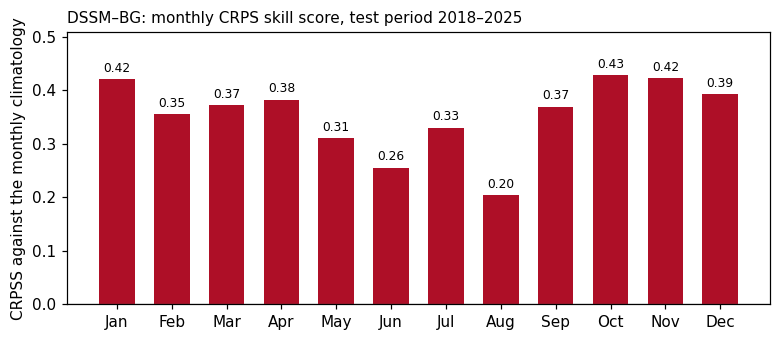

In [19]:
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
test_months = test_dates.month.to_numpy()
monthly = pd.Series([1 - crps_daily[test_months == m].mean() / crps_climatology_daily[test_months == m].mean() for m in range(1, 13)],
                    index=month_labels)

fig, ax = plt.subplots(figsize=(7.2, 3.2), dpi=110)
ax.bar(range(1, 13), monthly, width=0.65, color="#ae0f27")
for m, value in zip(range(1, 13), monthly):
    ax.text(m, value + 0.008, f"{value:.2f}", ha="center", va="bottom", fontsize=8)
ax.axhline(0, color="0.45", lw=0.8)
ax.set(xticks=range(1, 13), xticklabels=month_labels, ylabel="CRPSS against the monthly climatology", ylim=(0, monthly.max() + 0.08))
ax.set_title("DSSM–BG: monthly CRPS skill score, test period 2018–2025", loc="left", fontsize=10)
fig.tight_layout()
plt.show()

**Figure.** Monthly CRPS skill score of DSSM–BG at Tours against the monthly climatology.

**What the figure shows.**

- **Every month.** The skill is positive in every month: the predictors and the latent state add information beyond
  the seasonal cycle throughout the year.
- **Seasons.** It is highest in autumn and winter (about 0.4 in January, October and November) and lowest in summer,
  about 0.2 in August. Summer precipitation is often convective and local, and the daily predictors of one grid cell
  describe it poorly.

### 7.4 Calibration of the predictive distribution

The scores of Section 7.2 combine calibration and sharpness. Two diagnostics look at calibration alone (Gneiting et al., 2007):

- **Reliability diagram** of the wet-day probability: the test days are grouped by $\bar\pi_t$ in bins of width 0.1,
  and the observed frequency of wet days in each bin is plotted against the mean probability of the bin. A calibrated
  forecast lies on the diagonal, within the binomial sampling interval of the observed frequency.
- **Randomized PIT histogram** of the whole predictive distribution. With $F_t$ the predictive distribution function
  of day $t$, the probability integral transform of the observation is $u_t=F_t(y_t)$ on a wet day. On a dry day,
  $F_t$ jumps at zero, and $u_t$ is drawn uniformly on $[0,F_t(0)]$. For a calibrated forecast, the $u_t$ are uniform
  on $[0,1]$. $F_t$ is the mixture of the members,
  $F_t(u)=\frac{1}{N}\sum_n\bigl[1-\pi^{(n)}_t+\pi^{(n)}_t\,G(u-\tau;\alpha^{(n)}_t,\beta^{(n)}_t)\bigr]$ for $u>\tau$,
  with $G$ the Gamma distribution function.

In [ ]:
pi_members, alpha_members, beta_members = (prediction[k].astype(np.float64) for k in ("wet_probability", "alpha", "beta"))

# Reliability of the wet-day probability, in bins of width 0.1
edges = np.linspace(0, 1, 11)
bins = np.clip(np.digitize(pi_bar, edges) - 1, 0, 9)
reliability = pd.DataFrame({"p": pi_bar, "wet": observed > CFG.tau, "bin": bins}).groupby("bin").agg(
    forecast=("p", "mean"), observed=("wet", "mean"), days=("wet", "size"))
reliability["95% interval"] = 1.96 * np.sqrt(reliability.observed * (1 - reliability.observed) / reliability.days)
reliability.index = [f"{edges[b]:.1f}–{edges[b + 1]:.1f}" for b in reliability.index]

# Randomized PIT of the mixture of the members
dry_mass = (1 - pi_members).mean(axis=1)                                       # F_t(0) = F_t(tau)
excess = np.maximum(observed - CFG.tau, 0.0)[:, None]
wet_cdf = (1 - pi_members + pi_members * gammainc(alpha_members, beta_members * excess)).mean(axis=1)
u = np.where(observed > CFG.tau, wet_cdf, np.random.default_rng(0).uniform(size=len(observed)) * dry_mass)
n_pit_bins = 20
counts, pit_edges = np.histogram(u, bins=n_pit_bins, range=(0, 1))
expected = len(observed) / n_pit_bins
pit_band = 1.96 * np.sqrt(len(observed) * (1 / n_pit_bins) * (1 - 1 / n_pit_bins)) / expected   # 95% range of a bin, in density
chi2 = ((counts - expected) ** 2 / expected).sum()

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8), dpi=110, gridspec_kw={"width_ratios": (1, 1.3)})
axes[0].errorbar(reliability.forecast, reliability.observed, yerr=reliability["95% interval"], marker="o", ms=4, lw=1.2,
                 capsize=2, color="#ae0f27", label="DSSM–BG")
axes[0].plot([0, 1], [0, 1], color="0.45", ls="--", lw=0.8)
axes[0].set(xlim=(0, 1), ylim=(0, 1), aspect="equal", xlabel="forecast wet-day probability", ylabel="observed frequency of wet days")
axes[0].set_title("(a) Reliability of the wet-day probability", loc="left", fontsize=10)
axes[1].axhspan(1 - pit_band, 1 + pit_band, color="0.9", lw=0, label="95% range of a calibrated forecast")
axes[1].stairs(counts / expected, pit_edges, baseline=None, lw=1.5, color="#ae0f27", label="DSSM–BG")
axes[1].axhline(1, color="0.45", ls="--", lw=0.8)
axes[1].set(xlim=(0, 1), ylim=(0.5, 1.5), xlabel="PIT value", ylabel="density")
axes[1].set_title("(b) Randomized PIT histogram", loc="left", fontsize=10)
axes[1].legend(loc="lower center", ncol=2, frameon=False, fontsize=8)
fig.tight_layout()
plt.show()
display(reliability.round(3))
print(f"PIT: chi-square of the {n_pit_bins} bins {chi2:.1f} (p = {stats.chi2.sf(chi2, n_pit_bins - 1):.2f}; 5% critical value "
      f"{stats.chi2.ppf(0.95, n_pit_bins - 1):.1f}); {int((np.abs(counts / expected - 1) > pit_band).sum())} bins outside the 95% range; "
      f"variance of the PIT values {u.var():.4f} (uniform: {1 / 12:.4f})")

**Figure.** Calibration of DSSM–BG over 2018–2025. (a) Reliability diagram of the wet-day probability, in
bins of width 0.1, with the 95% binomial interval of the observed frequency (the table gives the mean probability, the
observed frequency and the number of days of each bin). (b) Randomized PIT histogram of the predictive distribution,
in 20 bins; a calibrated forecast gives a flat histogram at density 1, within the grey band in 95% of the bins.

### 7.5 Statistics of the simulated series: VALUE indices

In impact studies the simulated series are used directly, so they should also reproduce the statistics of the local
series (Maraun et al., 2015; Gutiérrez et al., 2019). Each member is treated as one simulation of the test period, and
each index $I$ is compared with the observed index through the relative bias $100\,(I(y^{(n)})-I(y))/I(y)$, summarized by its median and its 5–95% range over the 1000 members. The indices are those of Table 11:

| Index | Definition |
|---|---|
| R01 | wet-day frequency |
| SDII | mean amount of the wet days |
| P98 | 98th percentile of the wet-day amounts |
| WW, DW | probability of a wet day after a wet day, and after a dry day |
| Wet spell, dry spell | mean length of the wet spells and of the dry spells: number of wet (dry) days divided by the number of wet (dry) spells |

The Kolmogorov–Smirnov statistic KS, the largest distance between the empirical distribution functions of
the simulated and the observed wet-day amounts, compares the whole distribution of the amounts. Its 5% critical value uses the observed number of wet days and the median simulated number. The indices are
computed separately for each season (Maraun et al., 2019), so that errors of opposite sign in different seasons do not
cancel. Pairs of days and spells join only consecutive calendar days, so that a seasonal series is cut at the gaps
between the seasons of successive years. 

In [ ]:
TAU = CFG.tau
INDICES = ["R01", "SDII", "SD", "P95", "P98", "P99", "WW", "DW", "WetSpell", "DrySpell"]
SUMMARY = ["R01", "SDII", "P98", "WW", "DW", "WetSpell", "DrySpell"]   
QUANTILES = (5, 25, 75, 95)        # of the relative bias and of KS over the members
SEASONS = CFG.seasons


def indices(values, days, reference_wet=None):
    # Indices of every column of values (days x simulations); values at or below TAU are dry.
    values = np.where(values > TAU, values, 0.0)
    consecutive = np.diff(days) == 1
    wet = values > TAU
    amounts = np.where(wet, values, np.nan)
    previous, current = wet[:-1][consecutive], wet[1:][consecutive]
    # a spell starts on the first day, after a gap and when the state changes; mean length = days / spells
    start = np.vstack([np.ones((1, wet.shape[1]), bool), (wet[1:] != wet[:-1]) | ~consecutive[:, None]])
    result = {"R01": wet.mean(0), "SDII": np.nanmean(amounts, 0), "SD": values.std(0),
              "P95": np.nanpercentile(amounts, 95, 0), "P98": np.nanpercentile(amounts, 98, 0),
              "P99": np.nanpercentile(amounts, 99, 0), "WW": (previous & current).sum(0) / previous.sum(0),
              "DW": (~previous & current).sum(0) / (~previous).sum(0),
              "WetSpell": wet.sum(0) / (start & wet).sum(0), "DrySpell": (~wet).sum(0) / (start & ~wet).sum(0)}
    if reference_wet is not None:
        result["KS"] = np.array([ks_2samp(values[wet[:, k], k], reference_wet).statistic for k in range(values.shape[1])])
    return pd.DataFrame(result)


def median_bias(simulated, observed, days, mask, ks=True):
    # Median over the members of the relative bias (%) of every index, its mean and its 5, 25, 75 and 95% quantiles over
    # the members, the median KS statistic and its quantiles, and the 5% critical value of the two-sample KS test (observed
    # and median simulated wet days).
    obs = indices(observed[mask][:, None], days[mask]).iloc[0]
    sim = indices(simulated[mask], days[mask], observed[mask][observed[mask] > TAU] if ks else None)
    row = {}
    for k in INDICES:
        rb = 100 * (sim[k] - obs[k]) / obs[k]
        row[k], row[f"{k}_mean"] = np.median(rb), np.mean(rb)
        row.update({f"{k}_q{q:02d}": np.percentile(rb, q) for q in QUANTILES})
    if ks:
        n, m = (observed[mask] > TAU).sum(), np.median((simulated[mask] > TAU).sum(0))
        row["KS"], row["KS_crit"] = np.median(sim.KS), 1.358 * np.sqrt((n + m) / (n * m))
        row.update({f"KS_q{q:02d}": np.percentile(sim.KS, q) for q in QUANTILES})
    return row


def masks(dates):
    # Whole test period and the four seasons.
    return {"Annual": np.ones(len(dates), bool), **{s: dates.month.isin(m) for s, m in SEASONS.items()}}


days = test_dates.values.astype("datetime64[D]").astype(np.int64)
members = prediction["rainfall"].astype(np.float64)
bias = pd.DataFrame({group: median_bias(members, observed, days, mask) for group, mask in masks(test_dates).items()}).T

names = {"R01": "R01", "SDII": "SDII", "P98": "P98", "WW": "WW", "DW": "DW", "WetSpell": "wet-spell length",
         "DrySpell": "dry-spell length", "KS": "KS statistic"}
seasons = list(SEASONS)
fig, axes = plt.subplots(2, 4, figsize=(10.5, 5.0), dpi=110, sharex=True)
for ax, index in zip(axes.flat, SUMMARY + ["KS"]):
    median = bias.loc[seasons, index].astype(float)
    low, high = bias.loc[seasons, f"{index}_q05"].astype(float), bias.loc[seasons, f"{index}_q95"].astype(float)
    ax.errorbar(range(4), median, yerr=[median - low, high - median], fmt="o", ms=5, color="#ae0f27", elinewidth=1.2, capsize=3,
                label="median and 5–95% range over the members")
    if index == "KS":
        ax.plot(range(4), bias.loc[seasons, "KS_crit"], "_", ms=16, color="black", label="5% critical value of the KS test")
    else:
        ax.axhline(0, color="0.45", lw=0.8)
    ax.set(xticks=range(4), xticklabels=seasons)
    ax.set_title(names[index], loc="left", fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel("relative bias (%)")
axes[1, 3].set_ylabel("statistic")
handles, labels = axes[1, 3].get_legend_handles_labels()
fig.legend(handles, labels, ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.02), frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

bias[SUMMARY + ["KS", "KS_crit"]].astype(float).round(2)

**Figure.** VALUE indices of DSSM–BG in each season of the test period: median and 5–95% range over the
1000 simulations of the relative bias of each index, and of the KS statistic. Zero is the observed index. The table
gives the medians, with the whole test period in the row *Annual*.

### 7.6 Heavy precipitation

The 98th percentile shows how often the simulations produce large amounts, but not whether they produce them on the right days. Looks at the test days above the 99th percentile of the wet-day amounts of 1980–2017, and checks whether the observation lies above the 95th percentile of the members.

In [ ]:
reference_wet = y_all[(dates <= "2017-12-31") & wet]
p99 = np.percentile(reference_wet, 99)
top = np.flatnonzero(observed > p99)
members_top = prediction["rainfall"][top]
heavy = pd.DataFrame({"observed (mm)": observed[top], "mean wet-day probability": pi_bar[top],
                      "median": np.median(members_top, axis=1), "90th percentile": np.percentile(members_top, 90, axis=1),
                      "95th percentile": np.percentile(members_top, 95, axis=1), "largest member": members_top.max(axis=1),
                      "members above the observation (%)": 100 * (members_top > observed[top][:, None]).mean(axis=1)},
                     index=pd.Index(test_dates[top].date, name="test day"))
print(f"99th percentile of the wet-day amounts of 1980–2017: {p99:.1f} mm; {len(top)} test days above it; the observation lies "
      f"above the 95th percentile of the members on {(heavy['observed (mm)'] > heavy['95th percentile']).sum()} of them")
heavy.round(2)

## 8. References

- Burda, Y., Grosse, R. and Salakhutdinov, R. (2016). Importance weighted autoencoders. *International Conference on
  Learning Representations*.
- Chen, K., Yan, Z.-J. and Huo, Q. (2015). Training deep bidirectional LSTM acoustic model for LVCSR by a
  context-sensitive-chunk BPTT approach. *Proceedings of Interspeech 2015*, 3600–3604.
- Chung, J., Kastner, K., Dinh, L., Goel, K., Courville, A. and Bengio, Y. (2015). A recurrent latent variable model for
  sequential data. *Advances in Neural Information Processing Systems*, 28.
- Ferro, C. A. T. (2014). Fair scores for ensemble forecasts. *Quarterly Journal of the Royal Meteorological Society*, 140.
- Fraccaro, M., Sønderby, S. K., Paquet, U. and Winther, O. (2016). Sequential neural models with stochastic layers.
  *Advances in Neural Information Processing Systems*, 29, 2207–2215.
- Gneiting, T., Balabdaoui, F. and Raftery, A. E. (2007). Probabilistic forecasts, calibration and sharpness.
  *Journal of the Royal Statistical Society: Series B*, 69(2), 243–268. https://doi.org/10.1111/j.1467-9868.2007.00587.x
- Gneiting, T. and Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the
  American Statistical Association*, 102, 359–378. https://doi.org/10.1198/016214506000001437
- Gutiérrez, J. M. et al. (2019). An intercomparison of a large ensemble of statistical downscaling methods over
  Europe: results from the VALUE perfect predictor cross-validation experiment. *International Journal of
  Climatology*, 39, 3750–3785. https://doi.org/10.1002/joc.5462
- Hersbach, H. et al. (2020). The ERA5 global reanalysis. *Quarterly Journal of the Royal Meteorological Society*, 146,
  1999–2049. https://doi.org/10.1002/qj.3803
- Klein Tank, A. M. G. et al. (2002). Daily dataset of 20th-century surface air temperature and precipitation series
  for the European Climate Assessment. *International Journal of Climatology*, 22, 1441–1453.
  https://doi.org/10.1002/joc.773
- Krishnan, R. G., Shalit, U. and Sontag, D. (2017). Structured inference networks for nonlinear state space models.
  *Proceedings of the Thirty-First AAAI Conference on Artificial Intelligence*, 2101–2109.
- Maraun, D. et al. (2015). VALUE: A framework to validate downscaling approaches for climate change studies.
  *Earth's Future*, 3, 1–14. https://doi.org/10.1002/2014EF000259
- Maraun, D. et al. (2019). The VALUE perfect predictor experiment: evaluation of temporal variability.
  *International Journal of Climatology*, 39, 3786–3818. https://doi.org/10.1002/joc.5222
- Rainforth, T., Kosiorek, A. R., Le, T. A., Maddison, C. J., Igl, M., Wood, F. and Teh, Y. W. (2018). Tighter
  variational bounds are not necessarily better. *Proceedings of the 35th International Conference on Machine
  Learning*, PMLR 80.
- Tucker, G., Lawson, D., Gu, S. and Maddison, C. J. (2019). Doubly reparameterized gradient estimators for Monte
  Carlo objectives. *International Conference on Learning Representations*.